# 03. Entrenamiento de modelos

Tres algoritmos con fundamentos distintos, una línea base de una sola variable y una verificación de sobreajuste y subajuste.

In [1]:
import sys, json, warnings
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.utils import cargar_config, ruta, guardar_json, leer_json
CFG = cargar_config()
FIG = ruta(CFG["rutas"]["figuras"]); MET = ruta(CFG["rutas"]["metricas"])
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
C1, C2, C3, C4 = "#1F3A5F", "#C0504D", "#7F7F7F", "#E1A93B"
def guardar(nombre):
    plt.tight_layout(); plt.savefig(FIG / nombre, bbox_inches="tight"); plt.show()
from sklearn.metrics import roc_auc_score, roc_curve, average_precision_score, brier_score_loss
from src.data_processing import FEATURES
from src.model import crear_gradient_boosting, crear_random_forest, crear_regresion_logistica
from src.evaluate import cargar_particiones
train, test = cargar_particiones(CFG)
Xtr, ytr, Xte, yte = train[FEATURES], train.no_show, test[FEATURES], test.no_show

In [2]:
modelos = {'Regresión logística': crear_regresion_logistica(), 'Random Forest': crear_random_forest(42), 'Gradient Boosting': crear_gradient_boosting(42)}
filas, probs = [], {}
for n, m in modelos.items():
    m.fit(Xtr, ytr); p = m.predict_proba(Xte)[:,1]; probs[n] = p
    filas.append({'modelo': n, 'AUC-ROC': roc_auc_score(yte,p), 'AUC-PR': average_precision_score(yte,p), 'Brier': brier_score_loss(yte,p), 'AUC entrenamiento': roc_auc_score(ytr, m.predict_proba(Xtr)[:,1])})
base = crear_regresion_logistica().fit(Xtr[['lead_time_days']], ytr); pb = base.predict_proba(Xte[['lead_time_days']])[:,1]
filas.append({'modelo':'Referencia: solo antelación','AUC-ROC':roc_auc_score(yte,pb),'AUC-PR':average_precision_score(yte,pb),'Brier':brier_score_loss(yte,pb)})
filas.append({'modelo':'Sin información','AUC-ROC':0.5,'AUC-PR':yte.mean(),'Brier':brier_score_loss(yte, np.full(len(yte), ytr.mean()))})
tabla = pd.DataFrame(filas).round(4); tabla.to_csv(MET/'modelos_iniciales.csv', index=False); tabla

,modelo,AUC-ROC,AUC-PR,Brier,AUC entrenamiento
0,Regresión logística,0.6655,0.3053,0.1542,0.6632
1,Random Forest,0.7338,0.3660,0.1441,0.7486
2,Gradient Boosting,0.7397,0.3757,0.1426,0.7745
3,Referencia: solo antelación,0.7021,0.3111,0.1561,NaN
4,Sin información,0.5000,0.2019,0.1612,NaN


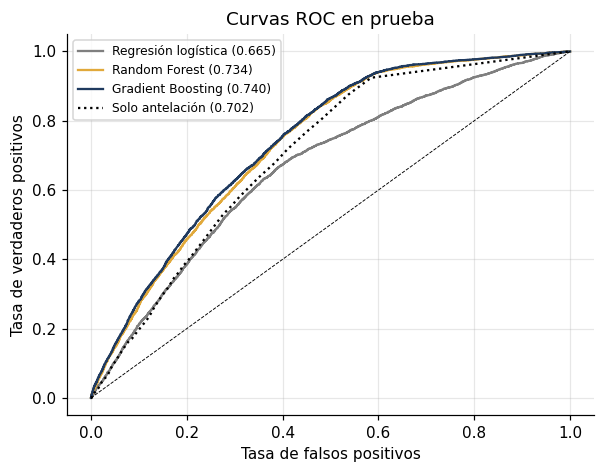

In [3]:
fig, ax = plt.subplots(figsize=(5.6,4.4))
for (n,p),c in zip(probs.items(), [C3,C4,C1]):
    f,t,_ = roc_curve(yte,p); ax.plot(f,t,color=c,label=f'{n} ({roc_auc_score(yte,p):.3f})')
f,t,_ = roc_curve(yte,pb); ax.plot(f,t,':',color='k',label=f'Solo antelación ({roc_auc_score(yte,pb):.3f})')
ax.plot([0,1],[0,1],'k--',lw=.6); ax.set_xlabel('Tasa de falsos positivos'); ax.set_ylabel('Tasa de verdaderos positivos'); ax.legend(fontsize=8); ax.set_title('Curvas ROC en prueba')
guardar('09_roc.png')

## Sobreajuste y subajuste
Random Forest con tres profundidades: la brecha entre AUC de entrenamiento y prueba revela el sobreajuste.

In [4]:
rows = []
for nombre, kw in [('max_depth=3', dict(max_depth=3, min_samples_leaf=50, n_estimators=200)), ('max_depth=8', dict(max_depth=8, min_samples_leaf=20)), ('sin límite', dict(max_depth=None, min_samples_leaf=1, n_estimators=200))]:
    m = crear_random_forest(42, **kw).fit(Xtr, ytr)
    rows.append({'configuración': nombre, 'AUC entrenamiento': roc_auc_score(ytr, m.predict_proba(Xtr)[:,1]), 'AUC prueba': roc_auc_score(yte, m.predict_proba(Xte)[:,1])})
sa = pd.DataFrame(rows); sa['brecha'] = sa['AUC entrenamiento'] - sa['AUC prueba']; sa.round(3)

,configuración,AUC entrenamiento,AUC prueba,brecha
0,max_depth=3,0.711,0.710,0.001
1,max_depth=8,0.749,0.734,0.015
2,sin límite,0.999,0.701,0.298


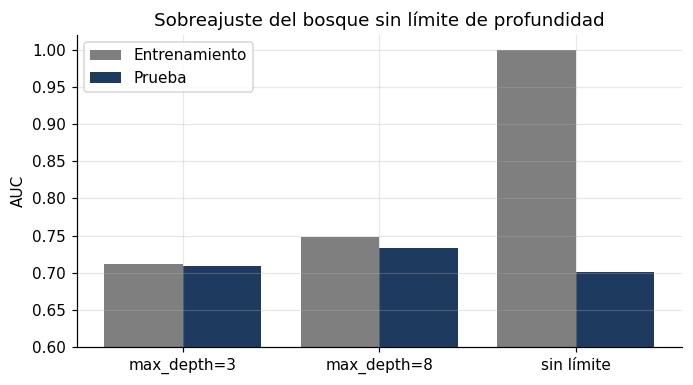

In [5]:
x = np.arange(len(sa)); fig, ax = plt.subplots(figsize=(6.4,3.6))
ax.bar(x-.2, sa['AUC entrenamiento'], .4, color=C3, label='Entrenamiento'); ax.bar(x+.2, sa['AUC prueba'], .4, color=C1, label='Prueba')
ax.set_xticks(x, sa['configuración']); ax.set_ylim(.6,1.02); ax.set_ylabel('AUC'); ax.legend(); ax.set_title('Sobreajuste del bosque sin límite de profundidad')
guardar('10_sobreajuste.png')

## Conclusión
Gradient Boosting es el mejor en las tres métricas, aunque solo supera por ~0.04 de AUC al modelo que únicamente usa la antelación. La regresión logística subajusta (queda por debajo de la referencia) porque la relación con la antelación no es lineal. El modelo inicial se guarda como `models/model_v1.pkl` (lo hace `src/train.py`).